In [11]:
import os

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle

from helpers.benchmark import load_records_from_directory, metric_for_benchmark, remove_cold_starts, trim_on_benchmark
from helpers.cpus import get_cpu_color, shorten_cpu_name
from helpers.style import use_paper_style

use_paper_style()

LOG_DIR = "data/stage_b"

STAGE_B_CONFIGS = [
    ("aws", [128, 512, 2048]),
    ("gcp", [128, 512, 2048]),
    ("alibaba", [128, 512, 2048]),
    ("azure", [512, 2048]),
]

PROVIDER_DISPLAY = {"aws": "AWS", "azure": "Azure", "gcp": "GCF", "alibaba": "Alibaba"}


df_raw = load_records_from_directory(LOG_DIR)
df = remove_cold_starts(df_raw)


allowed = {(p, m) for (p, mems) in STAGE_B_CONFIGS for m in mems}
df = df[df.apply(lambda r: (r["provider"], r["memory_size_mb"]) in allowed, axis=1)].copy()


trimmed_df  = pd.DataFrame()
for provider, mem_sizes in STAGE_B_CONFIGS:
    for mem_size in mem_sizes:
        df_subset = df[
            (df["provider"] == provider)
            & (df["memory_size_mb"] == mem_size)
        ]
        
        df_subset = trim_on_benchmark(df_subset, group_on_timestamp=False, benchmark="matmul")
        trimmed_df = pd.concat([trimmed_df, df_subset], ignore_index=True)


print("raw rows:", len(df_raw))
print("filtered rows:", len(df))


print("\nRecords per provider/memory:")
print(df.groupby(["provider", "memory_size_mb"]).size().unstack(fill_value=0))
print("\nTrimmed records per provider/memory:")
print(trimmed_df.groupby(["provider", "memory_size_mb"]).size().unstack(fill_value=0))

raw rows: 195834
filtered rows: 137566

Records per provider/memory:
memory_size_mb   128    512    2048
provider                           
alibaba         11765  12495  12974
aws             11983  12669  12682
azure               0  12764  12592
gcp             11886  12539  13217

Trimmed records per provider/memory:
memory_size_mb   128    512    2048
provider                           
alibaba         11646  12369  12844
aws             11860  12540  12553
azure               0  12634  12464
gcp             11765  12411  13082


Saved: plots/stage_b/cpu_composition_2x2.pdf


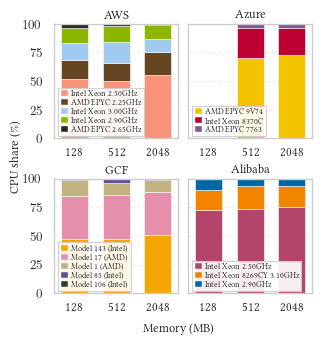

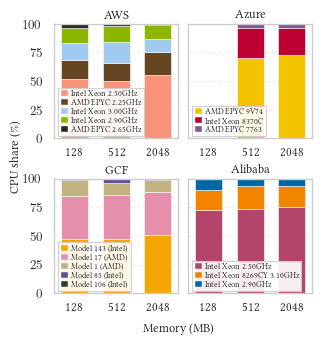

In [12]:
def plot_stage_b_cpu_composition_2x2(
    df: pd.DataFrame,
    save_path: str | None = None,
    show: bool = True,
):
    providers_grid = [["aws", "azure"], ["gcp", "alibaba"]]
    memory_sizes = [128, 512, 2048]

    rows = []
    for row in providers_grid:
        for provider in row:
            for mem in memory_sizes:
                sub = df[
                    (df["provider"] == provider)
                    & (df["memory_size_mb"] == mem)
                    & (df["benchmark_type"] == "matmul")
                ].copy()
                if sub.empty:
                    continue
                cpu_counts = sub["cpu_type"].value_counts(dropna=True)
                total = int(cpu_counts.sum())
                if total <= 0:
                    continue
                for cpu, count in cpu_counts.items():
                    rows.append({
                        "provider": provider,
                        "memory_size": mem,
                        "cpu_type": cpu,
                        "percentage": (count / total) * 100.0,
                    })

    results_df = pd.DataFrame(rows)
    if results_df.empty:
        raise ValueError("No data found after filtering.")

    fig = plt.figure(figsize=(3.33, 3.5))
    outer_gs = gridspec.GridSpec(
        2, 2,
        height_ratios=[1, 1],
        width_ratios=[1, 1],
        hspace=0.35,
        wspace=0.08,
        figure=fig,
    )

    axes = [[None, None], [None, None]]
    for r in range(2):
        for c in range(2):
            axes[r][c] = fig.add_subplot(outer_gs[r, c])

    bar_width = 0.65
    x = np.arange(len(memory_sizes))

    for row_idx, row_providers in enumerate(providers_grid):
        for col_idx, provider in enumerate(row_providers):
            ax = axes[row_idx][col_idx]
            pdata = results_df[results_df["provider"] == provider].copy()

            cpu_order = (
                pdata.groupby("cpu_type")["percentage"]
                .sum()
                .sort_values(ascending=False)
                .index.tolist()
            ) if not pdata.empty else []

            wide = (
                pdata.pivot_table(
                    index="memory_size",
                    columns="cpu_type",
                    values="percentage",
                    aggfunc="sum",
                    fill_value=0.0,
                )
                .reindex(index=memory_sizes, fill_value=0.0)
                .reindex(columns=cpu_order, fill_value=0.0)
            ) if cpu_order else pd.DataFrame(
                0.0, index=memory_sizes, columns=[]
            )

            bottom = np.zeros(len(memory_sizes))
            legend_handles = []
            legend_labels = []

            for cpu in cpu_order:
                vals = wide[cpu].to_numpy(dtype=float)
                color = get_cpu_color(cpu, provider=provider)

                ax.bar(
                    x, vals, bottom=bottom, width=bar_width,
                    color=color, edgecolor="white", linewidth=0.4,
                )
                bottom += vals

                legend_handles.append(
                    Patch(facecolor=color, edgecolor="white", linewidth=0.3)
                )
                legend_labels.append(shorten_cpu_name(cpu))

            ax.set_xticks(x)
            ax.set_xticklabels([str(m) for m in memory_sizes])
            ax.set_ylim(0, 100)
            ax.set_title(
                PROVIDER_DISPLAY[provider],
                fontweight="bold", pad=4, fontsize=9,
            )
            ax.tick_params(axis="x", pad=2)
            ax.grid(True, axis="y", linestyle="--", alpha=0.3)
            ax.grid(False, axis="x")
            ax.set_xlim(-0.5, len(memory_sizes) - 0.5)

            if col_idx > 0:
                ax.set_yticklabels([])

            if legend_handles:
                ax.legend(
                    legend_handles, legend_labels,
                    loc="lower left",
                    fontsize=6,
                    bbox_to_anchor=(0, -0.02),
                    frameon=True,
                    framealpha=0.9,
                    edgecolor="#cccccc",
                    fancybox=False,
                    handlelength=0.9,
                    handletextpad=0.3,
                    labelspacing=0.15,
                    borderpad=0.3,
                )

    fig.text(
        0.01, 0.5, "CPU share (\\%)",
        va="center", ha="center",
        rotation="vertical",
        fontweight="bold",
    )
    fig.text(
        0.5, 0.01, "Memory (MB)",
        va="center", ha="center",
        fontweight="bold",
    )

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


plot_stage_b_cpu_composition_2x2(
    df,
    save_path="plots/stage_b/cpu_composition_2x2.pdf",
    show=True,
)

Saved: plots/stage_b/deviation_from_median_2x2.pdf


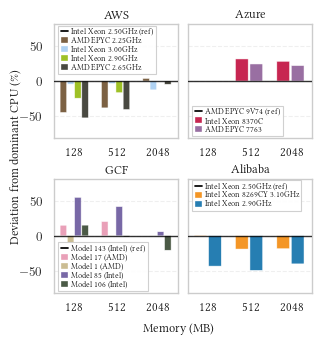

In [13]:
def plot_stage_b_deviation_2x2(
    df: pd.DataFrame,
    trimmed_df: pd.DataFrame,
    save_path: str | None = None,
    show: bool = True,
) -> plt.Figure:

    providers_grid = [["aws", "azure"], ["gcp", "alibaba"]]
    memory_sizes = [128, 512, 2048]
    metric = metric_for_benchmark("matmul")

    fig = plt.figure(figsize=(3.33, 3.5))
    outer_gs = gridspec.GridSpec(
        2, 2,
        height_ratios=[1, 1],
        width_ratios=[1, 1],
        hspace=0.35,
        wspace=0.08,
        figure=fig,
    )

    axes = [[None, None], [None, None]]
    for r in range(2):
        for c in range(2):
            axes[r][c] = fig.add_subplot(outer_gs[r, c])

    x = np.arange(len(memory_sizes))
    global_changes = []

    legend_locs = {
        "aws":     ("upper left",  (0, 1.02)),
        "azure":   ("lower left",  (0, -0.02)),
        "gcp":     ("lower left",  (0, -0.02)),
        "alibaba": ("upper left",  (0, 1.02)),
    }

    for row_idx, row_providers in enumerate(providers_grid):
        for col_idx, provider in enumerate(row_providers):
            ax = axes[row_idx][col_idx]

            ax.set_xticks(x)
            ax.set_xticklabels([str(m) for m in memory_sizes])
            ax.set_xlim(-0.5, len(memory_sizes) - 0.5)
            ax.set_title(PROVIDER_DISPLAY[provider], fontweight="bold", pad=4, fontsize=9)
            ax.tick_params(axis="x", pad=2)
            ax.grid(True, axis="y", linestyle="--", alpha=0.3, zorder=0)
            ax.grid(False, axis="x")
            if col_idx > 0:
                ax.set_yticklabels([])

            trimmed_provider_df = trimmed_df[
                (trimmed_df["provider"] == provider)
                & (trimmed_df["benchmark_type"] == "matmul")
            ]
            provider_df = df[
                (df["provider"] == provider)
                & (df["benchmark_type"] == "matmul")
            ]

            provider_cpu_order = (
                trimmed_provider_df.groupby("cpu_type")["instance_id"]
                .nunique()
                .sort_values(ascending=False)
                .index.tolist()
            )
            if not provider_cpu_order:
                continue

            dominant_CPU = provider_cpu_order[0]
            non_dominant = [c for c in provider_cpu_order if c != dominant_CPU]
            n_cpus = len(non_dominant)

            all_plot_data = {}
            for mem in memory_sizes:
                config_df = trimmed_provider_df[trimmed_provider_df["memory_size_mb"] == mem]
                config_raw_df = provider_df[provider_df["memory_size_mb"] == mem]
                if config_df.empty:
                    continue
                cpu_medians = config_raw_df.groupby("cpu_type")[metric].median()
                dominant_median = cpu_medians.get(dominant_CPU, np.nan)
                all_plot_data[mem] = {
                    cpu: (m - dominant_median) / dominant_median * 100.0
                    for cpu, m in cpu_medians.items()
                }

            if n_cpus > 0:
                dev_bar_width = min(0.7 / n_cpus, 0.35)
                total_group_width = n_cpus * dev_bar_width

                for mem_idx, mem in enumerate(memory_sizes):
                    pct_map = all_plot_data.get(mem, {})
                    if not pct_map:
                        continue

                    start_x = x[mem_idx] - total_group_width / 2

                    for bar_idx, cpu in enumerate(non_dominant):
                        if cpu not in pct_map:
                            continue
                        pct_change = float(pct_map[cpu])
                        color = get_cpu_color(cpu, provider=provider)
                        x_pos = start_x + bar_idx * dev_bar_width
                        bar_w = dev_bar_width * 0.85

                        if pct_change < 0:
                            patch = FancyBboxPatch(
                                (x_pos, pct_change), bar_w, -pct_change,
                                boxstyle="round,pad=0.005",
                                edgecolor="white", facecolor=color,
                                linewidth=0.4, alpha=0.85,
                            )
                        else:
                            patch = FancyBboxPatch(
                                (x_pos, 0), bar_w, pct_change,
                                boxstyle="round,pad=0.005",
                                edgecolor="white", facecolor=color,
                                linewidth=0.4, alpha=0.85,
                            )
                        ax.add_patch(patch)
                        global_changes.append(pct_change)

            ax.axhline(0, color="black", linestyle="-",
                       linewidth=1, alpha=0.8, zorder=10)

            legend_handles = []
            for cpu in provider_cpu_order:
                if cpu == dominant_CPU:
                    legend_handles.append(Line2D([0], [0], color="black", linewidth=1.25))
                else:
                    legend_handles.append(
                        Rectangle((0, 0), 1, 1,
                                  facecolor=get_cpu_color(cpu, provider),
                                  edgecolor="white", linewidth=0.3, alpha=0.85)
                    )
            legend_labels = [shorten_cpu_name(cpu) for cpu in provider_cpu_order]
            legend_labels[provider_cpu_order.index(dominant_CPU)] += " (ref)"

            loc, anchor = legend_locs[provider]
            ax.legend(
                legend_handles, legend_labels,
                loc=loc, bbox_to_anchor=anchor,
                fontsize=6, frameon=True, framealpha=0.92,
                edgecolor="#cccccc", fancybox=False,
                handlelength=0.9, handletextpad=0.3,
                labelspacing=0.15, borderpad=0.3,
            )

    if global_changes:
        max_abs = max(abs(min(global_changes)), abs(max(global_changes)))
        pad = 5
        for r in range(2):
            for c in range(2):
                axes[r][c].set_ylim(-(max_abs * 1.4 + pad),
                                     (max_abs * 1.4 + pad))

    fig.text(0.01, 0.5, "Deviation from dominant CPU (\\%)",
             va="center", ha="center", rotation="vertical", fontweight="bold")
    fig.text(0.5, 0.01, "Memory (MB)",
             va="center", ha="center", fontweight="bold")

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig

fig = plot_stage_b_deviation_2x2(
    df=df,
    trimmed_df=trimmed_df,
    save_path="plots/stage_b/deviation_from_median_2x2.pdf",
)

Saved: plots/stage_b/azure_bimodality_ecdf.pdf


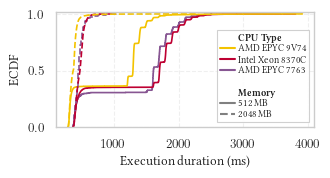

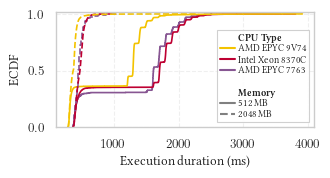

In [14]:
def plot_azure_bimodality_ecdf(
    df: pd.DataFrame,
    memory_configs: list[int] | None = None,
    save_path: str | None = None,
    show: bool = True,
):
    memory_configs = memory_configs or [512, 2048]

    provider_df = df[
        (df["provider"] == "azure")
        & (df["benchmark_type"] == "matmul")
        & (df["memory_size_mb"].isin(memory_configs))
    ].copy()

    if provider_df.empty:
        print("No data found for Azure matmul")
        return None

    metric_field = metric_for_benchmark("matmul")
    provider_df[metric_field] = pd.to_numeric(provider_df[metric_field], errors="coerce")
    provider_df = provider_df.dropna(subset=[metric_field])

    provider_df["cpu_short"] = provider_df["cpu_type"].apply(shorten_cpu_name)

    cpu_order = (
        provider_df.groupby("cpu_short")
        .size()
        .sort_values(ascending=False)
        .index.tolist()
    )

    palette = {
        shorten_cpu_name(cpu): get_cpu_color(cpu, "azure")
        for cpu in provider_df["cpu_type"].unique()
    }

    line_styles = ["-", "--", ":"]
    style_map = {
        mem: line_styles[i % len(line_styles)]
        for i, mem in enumerate(memory_configs)
    }

    fig, ax = plt.subplots(figsize=(3.33, 1.5))

    for mem in memory_configs:
        mem_subset = provider_df[provider_df["memory_size_mb"] == mem]
        if mem_subset.empty:
            continue
        sns.ecdfplot(
            data=mem_subset,
            x=metric_field,
            hue="cpu_short",
            hue_order=cpu_order,
            palette=palette,
            linestyle=style_map[mem],
            linewidth=1.2,
            ax=ax,
            legend=False,
        )

    ax.set_xlabel("Execution duration (ms)", fontweight="bold")
    ax.set_ylabel("ECDF", fontweight="bold")   
    ax.set_ylim(0, 1.02)
    ax.grid(True, axis="both", linestyle="--", alpha=0.3)

    legend_elements = []

    legend_elements.append(
        Line2D([0], [0], color="none", label="\\textbf{CPU Type}")
    )
    for cpu_short in cpu_order:
        legend_elements.append(
            Line2D([0], [0], color=palette[cpu_short], linewidth=1.5, label=cpu_short)
        )

    legend_elements.append(Line2D([0], [0], color="none", label=""))
    legend_elements.append(
        Line2D([0], [0], color="none", label="\\textbf{Memory}")
    )
    for mem in memory_configs:
        legend_elements.append(
            Line2D(
                [0], [0],
                color="gray", linestyle=style_map[mem],
                linewidth=1.5, label=f"{mem} MB",
            )
        )

    ax.legend(
        handles=legend_elements,
        loc="lower right",
        frameon=True,
        framealpha=0.92,
        fontsize=7,
        edgecolor="#cccccc",
        fancybox=False,
        handlelength=1.5,
        handletextpad=0.3,
        labelspacing=0.2,
        borderpad=0.3,
    )

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", format="pdf", dpi=300)
        print(f"Saved: {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig


plot_azure_bimodality_ecdf(
    df,
    memory_configs=[512, 2048],
    save_path="plots/stage_b/azure_bimodality_ecdf.pdf",
)

In [15]:
def summarize_stage_b(df: pd.DataFrame, trimmed_df: pd.DataFrame, benchmark: str = "matmul") -> pd.DataFrame:
    """
    One row per provider, memory size, and CPU type, plus an "all" row per configuration.
    Share, median, and the deviation from the dominant CPU use all invocations (as in the
    deviation figure); mean, std, CV, and percentiles use the trimmed data (as in the paper).
    The dominant CPU is the one with the most instances per provider, as in the figure.
    """
    metric = metric_for_benchmark(benchmark)
    raw = df[df["benchmark_type"] == benchmark]
    trim = trimmed_df[trimmed_df["benchmark_type"] == benchmark]

    dominant = {
        provider: g.groupby("cpu_type")["instance_id"].nunique().idxmax()
        for provider, g in trim.groupby("provider")
    }

    rows = []
    for provider, mems in STAGE_B_CONFIGS:
        for mem in mems:
            r_cfg = raw[(raw["provider"] == provider) & (raw["memory_size_mb"] == mem)]
            t_cfg = trim[(trim["provider"] == provider) & (trim["memory_size_mb"] == mem)]
            dom_median = r_cfg.loc[r_cfg["cpu_type"] == dominant[provider], metric].median()

            groups = [("all", r_cfg, t_cfg)] + [
                (cpu, r_cfg[r_cfg["cpu_type"] == cpu], t_cfg[t_cfg["cpu_type"] == cpu])
                for cpu in r_cfg["cpu_type"].value_counts().index
            ]
            for cpu, r, t in groups:
                dur = t[metric]
                ctx = t["context_switches_delta"]
                rows.append({
                    "provider": PROVIDER_DISPLAY[provider],
                    "memory_mb": mem,
                    "cpu": cpu if cpu == "all" else shorten_cpu_name(cpu) + (" (dom.)" if cpu == dominant[provider] else ""),
                    "n": len(r),
                    "share_%": len(r) / len(r_cfg) * 100,
                    "median_ms": r[metric].median(),
                    "dev_vs_dom_%": np.nan if cpu == "all" else (r[metric].median() - dom_median) / dom_median * 100,
                    "mean_ms": dur.mean(),
                    "std_ms": dur.std(),
                    "cv_%": dur.std() / dur.mean() * 100,
                    "p5_ms": dur.quantile(0.05),
                    "p95_ms": dur.quantile(0.95),
                    "ctx_sw_mean": ctx.mean(),
                    "ctx_sw_median": ctx.median(),
                })
    return pd.DataFrame(rows)


summary = summarize_stage_b(df, trimmed_df)
pd.set_option("display.max_rows", 200)
display(summary.round(1))

ctx = (
    trimmed_df[(trimmed_df["provider"] == "aws") & (trimmed_df["benchmark_type"] == "matmul")]
    .groupby(["cpu_type", "memory_size_mb"])["context_switches_delta"].mean()
    .unstack()
)
ctx = ctx.sort_values(128, ascending=False)
ctx["drop_128_to_2048_x"] = ctx[128] / ctx[2048]
ctx.index = [shorten_cpu_name(c) for c in ctx.index]
print("AWS Lambda: mean context switches per invocation")
display(ctx.round(1))
print(f"Per-CPU drop from 128 MB to 2048 MB: {ctx['drop_128_to_2048_x'].min():.1f}x to {ctx['drop_128_to_2048_x'].max():.1f}x")

,provider,memory_mb,cpu,n,share_%,median_ms,dev_vs_dom_%,mean_ms,std_ms,cv_%,p5_ms,p95_ms,ctx_sw_mean,ctx_sw_median
0,AWS,128,all,11983,100.0,11820.5,NaN,10566.4,2297.8,21.7,6380.1,12701.0,906.6,956.0
1,AWS,128,Intel Xeon 2.50GHz (dom.),6232,52.0,12161.7,0.0,12210.6,331.6,2.7,11741.6,12859.0,1010.4,1005.0
2,AWS,128,AMD EPYC 2.25GHz,2007,16.7,6662.5,-45.2,6683.3,236.6,3.5,6320.9,7081.1,704.9,689.0
3,AWS,128,Intel Xeon 3.00GHz,1719,14.3,11619.4,-4.5,11632.7,267.7,2.3,11238.8,12119.6,940.4,937.0
4,AWS,128,Intel Xeon 2.90GHz,1595,13.3,9160.0,-24.7,9179.5,315.4,3.4,8701.6,9738.2,796.8,785.0
5,AWS,128,AMD EPYC 2.65GHz,430,3.6,5719.5,-53.0,5731.7,194.2,3.4,5460.5,6061.1,616.9,617.0
6,AWS,512,all,12669,100.0,2638.7,NaN,2468.6,410.1,16.6,1622.1,2902.1,458.2,464.0
7,AWS,512,Intel Xeon 2.50GHz (dom.),6362,50.2,2738.7,0.0,2734.7,126.0,4.6,2535.5,2945.4,493.8,484.0
8,AWS,512,Intel Xeon 3.00GHz,2338,18.5,2642.2,-3.5,2630.8,139.8,5.3,2379.4,2840.6,487.1,478.0
9,AWS,512,AMD EPYC 2.25GHz,2000,15.8,1682.0,-38.6,1693.6,91.4,5.4,1564.1,1861.9,347.3,341.0


AWS Lambda: mean context switches per invocation


memory_size_mb,128,512,2048,drop_128_to_2048_x
Intel Xeon 2.50GHz,1010.4,493.8,112.0,9.0
Intel Xeon 3.00GHz,940.4,487.1,113.0,8.3
Intel Xeon 2.90GHz,796.8,433.4,173.0,4.6
AMD EPYC 2.25GHz,704.9,347.3,172.1,4.1
AMD EPYC 2.65GHz,616.9,334.8,165.2,3.7


Per-CPU drop from 128 MB to 2048 MB: 3.7x to 9.0x
